# Philadelphia Enrichment Access Gap
**Who has access to free programs in Philadelphia — and who doesn't?**

---

This notebook uses real open data from the City of Philadelphia to map where Parks & Recreation program sites are located, assign each one to a neighborhood, and explore how program access compares to poverty rates. Community recreation centers hold the key to a number of benefits that enhance the quality of life in your community. 

### Significance of this Project
Youth and the people of Philadelphia rely on recreational centers for entertainment, community relationship building, and having a safe space to socialize. They are homes to free fitness classes, afterschool programs, and offer life saving classes such as swimming and CPR training. Without rec centers or the lack of these free programs may negatively affect residents.

### Data sources
| File | Source | What it contains |
|------|--------|------------------|
| `PPR_Program_Sites.csv` | [OpenDataPhilly](https://www.opendataphilly.org/datasets/ppr-program-sites/) | 168 Philadelphia Parks & Rec locations |
| `philadelphia-neighborhoods.geojson` | [OpenDataPhilly](https://www.opendataphilly.org/datasets/philadelphia-neighborhoods/) | 159 official neighborhood boundaries |

## Section 1: Install and import libraries



In [80]:

%pip install geopandas pyproj plotly shapely folium --quiet

import pandas as pd
import geopandas as gpd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pyproj import Transformer
from shapely.geometry import Point
import warnings
warnings.filterwarnings('ignore')

print('All libraries loaded!')

Note: you may need to restart the kernel to use updated packages.
All libraries loaded!


In [81]:

PPR_FILE       = 'PPR_Program_Sites.csv'
NEIGHBORHOODS  = 'philadelphia-neighborhoods.geojson'

# Load PPR program sites
ppr = pd.read_csv(PPR_FILE)
print(f'PPR sites loaded: {ppr.shape[0]} rows × {ppr.shape[1]} columns')
ppr.head(3)

PPR sites loaded: 168 rows × 12 columns


,X,Y,park_name,dpp_asset_id,program_type,site_class,building,gym,label_number,comments,data_source,objectid
0,-8.367177e+06,4.873773e+06,Awbury Park and Recreation Center,NaN,PPR_REC,A,Y,N,NaN,,NaN,1
1,-8.349798e+06,4.883810e+06,Daniel Boyle Memorial Recreation Center,NaN,PPR_REC,A,Y,N,NaN,,NaN,2
2,-8.367867e+06,4.875347e+06,Charles M Finley Playground,NaN,PPR_REC,A,Y,Y,NaN,,NaN,3


In [38]:
# Load neighborhood boundaries (GeoJSON)
nbhd = gpd.read_file(NEIGHBORHOODS)
print(f'Neighborhoods loaded: {len(nbhd)} neighborhoods')
print('Columns:', nbhd.columns.tolist())
nbhd[['LISTNAME', 'Shape_Area']].head(10)

Neighborhoods loaded: 159 neighborhoods
Columns: ['NAME', 'LISTNAME', 'MAPNAME', 'Shape_Leng', 'Shape_Area', 'geometry']


,LISTNAME,Shape_Area
0,Bridesburg,4.458626e+07
1,Bustleton,1.140504e+08
2,Cedarbrook,2.487174e+07
3,Chestnut Hill,7.966498e+07
4,East Falls,4.057689e+07
5,"Mount Airy, East",4.315247e+07
6,Grays Ferry,3.131163e+07
7,Olney,5.030840e+07
8,Pennypack Park,6.014076e+07
9,Somerton,1.292546e+08


### I had to convert the coordinates so it would line up for the city of Philadelphia

In [82]:

transformer = Transformer.from_crs('EPSG:3857', 'EPSG:4326', always_xy=True)

ppr['longitude'], ppr['latitude'] = transformer.transform(
    ppr['X'].values,
    ppr['Y'].values
)

print('Latitude range:', ppr['latitude'].min(), '→', ppr['latitude'].max())
print('Longitude range:', ppr['longitude'].min(), '→', ppr['longitude'].max())

ppr[['park_name', 'program_type', 'longitude', 'latitude']].head(5)

Latitude range: 39.90443773947124 → 40.12284317236059
Longitude range: -75.25630044716199 → -74.96943963409582


,park_name,program_type,longitude,latitude
0,Awbury Park and Recreation Center,PPR_REC,-75.163634,40.053863
1,Daniel Boyle Memorial Recreation Center,PPR_REC,-75.007511,40.122843
2,Charles M Finley Playground,PPR_REC,-75.169832,40.064686
3,James Allen Shuler Playground,PPR_REC,-75.174764,40.002221
4,Marian Anderson Recreation Center,PPR_REC,-75.171519,39.942119


 ### Assigning each park to its neighborhood



In [70]:

ppr_geo = gpd.GeoDataFrame(
    ppr,
    geometry=gpd.points_from_xy(ppr['longitude'], ppr['latitude']),
    crs='EPSG:4326'   # same coordinate system as neighborhoods
)

# Step 2: Spatial join 
ppr_joined = gpd.sjoin(
    ppr_geo,
    nbhd[['LISTNAME', 'NAME', 'geometry']],
    how='left',          # keep all parks, even if no neighborhood matched
    predicate='within'   # park point must be WITHIN the neighborhood polygon
)

# Check how many parks got a neighborhood assigned
matched = ppr_joined['LISTNAME'].notna().sum()
total   = len(ppr_joined)
print(f'Parks matched to a neighborhood: {matched} / {total}')

# Rename for clarity
ppr_joined = ppr_joined.rename(columns={'LISTNAME': 'neighborhood'})

ppr_joined[['park_name', 'program_type', 'neighborhood', 'latitude', 'longitude']].head(10)

Parks matched to a neighborhood: 168 / 168


,park_name,program_type,neighborhood,latitude,longitude
0,Awbury Park and Recreation Center,PPR_REC,"Germantown, East",40.053863,-75.163634
1,Daniel Boyle Memorial Recreation Center,PPR_REC,Somerton,40.122843,-75.007511
2,Charles M Finley Playground,PPR_REC,West Oak Lane,40.064686,-75.169832
3,James Allen Shuler Playground,PPR_REC,Allegheny West,40.002221,-75.174764
4,Marian Anderson Recreation Center,PPR_REC,Graduate Hospital,39.942119,-75.171519
5,Howard Sayre Morris Recreation Center,PPR_REC,Cobbs Creek,39.956693,-75.238566
6,Frank Glavin Playground,PPR_REC,Richmond,39.986466,-75.101296
7,East Fairmount Park,PPR_REC,East Park,39.969055,-75.185091
8,John C Anderson Cultural Center,PPR_REC,Overbrook,39.995218,-75.233243
9,William A Cibotti Recreation Center,PPR_REC,Clearview,39.908161,-75.248617


### Count programs per neighborhood



In [74]:
# Count parks per neighborhood
ppr_joined['neighborhood'].value_counts()


print(f'Neighborhoods with at least 1 PPR site: {len(nbhd_counts)}')
print(f'Neighborhoods with NO PPR site: {159 - len(nbhd_counts)}')
print()
print('Top 10 neighborhoods by number of PPR sites:')
nbhd_counts.head(10)

Neighborhoods with at least 1 PPR site: 92
Neighborhoods with NO PPR site: 67

Top 10 neighborhoods by number of PPR sites:


,neighborhood,total_sites
47,Mantua,6
60,Overbrook,5
80,Tacony,5
70,Richmond,5
11,Cobbs Creek,5
59,Olney,4
85,West Oak Lane,4
32,Grays Ferry,4
86,West Park,3
55,North Central,3


In [1]:
#
pivot_df = (
    ppr_joined
    .dropna(subset=['neighborhood'])
    .groupby(['program_type', 'neighborhood'])
    .size()
    .unstack(level='neighborhood', fill_value=0)  # neighborhoods become columns
)

print('Pivot table shape:', pivot_df.shape)
print('Rows (program types):', pivot_df.index.tolist())
print(f'Columns (neighborhoods): {pivot_df.shape[1]} neighborhoods')
print()
#first 8 neighborhoods
pivot_df.iloc[:, :8]

NameError: name 'ppr_joined' is not defined

In [84]:

pivot_with_total = pivot_df.copy()
pivot_with_total.loc['TOTAL'] = pivot_with_total.sum()


sorted_cols = pivot_with_total.loc['TOTAL'].sort_values(ascending=False).index
pivot_sorted = pivot_with_total[sorted_cols]

print('Top 15 neighborhoods by total PPR sites:')
pivot_sorted.loc['TOTAL'].head(15)

Top 15 neighborhoods by total PPR sites:


neighborhood
Mantua                         6
Overbrook                      5
Tacony                         5
Richmond                       5
Cobbs Creek                    5
Olney                          4
West Oak Lane                  4
Grays Ferry                    4
West Park                      3
North Central                  3
Germantown, East               3
Frankford                      3
Hartranft                      3
Holmesburg                     3
Fishtown - Lower Kensington    3
Name: TOTAL, dtype: int64

In [85]:

pivot_sorted.to_csv('ppr_pivot_neighborhood_columns.csv')


## Where are the programs located?

Chart 1: Shows PPR Program Sites by their types(pool, environmental education center, older adult centers, and traditional recreational centers)

Chart 2: Shows how many program sites are in each Philly neighborhood.

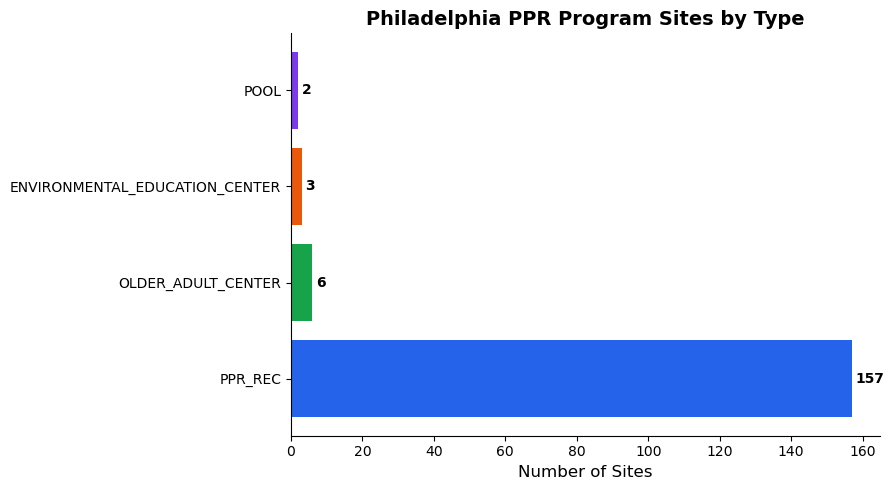

Saved: chart1_program_types.png


In [48]:
# Chart 1: Program types breakdown
type_counts = ppr_joined['program_type'].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2563eb', '#16a34a', '#ea580c', '#7c3aed']
bars = ax.barh(type_counts.index, type_counts.values, color=colors[:len(type_counts)])

# Add count labels on each bar
for bar, val in zip(bars, type_counts.values):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontweight='bold')

ax.set_xlabel('Number of Sites', fontsize=12)
ax.set_title('Philadelphia PPR Program Sites by Type', fontsize=14, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('chart1_program_types.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: chart1_program_types.png')

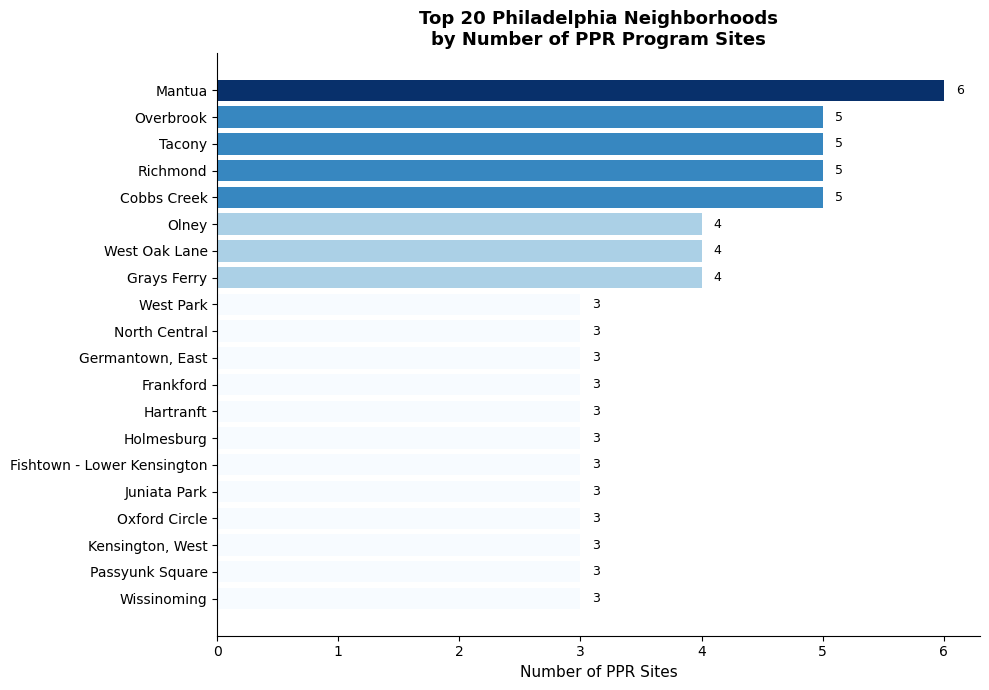

Saved: chart2_top_neighborhoods.png


In [49]:
# Chart 2: Top 20 neighborhoods by PPR site count
top20 = nbhd_counts.head(20)

fig, ax = plt.subplots(figsize=(10, 7))
norm = plt.Normalize(top20['total_sites'].min(), top20['total_sites'].max())
colors = cm.Blues(norm(top20['total_sites'].values))

bars = ax.barh(top20['neighborhood'][::-1], top20['total_sites'][::-1], color=colors[::-1])

for bar, val in zip(bars, top20['total_sites'][::-1]):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=9)

ax.set_xlabel('Number of PPR Sites', fontsize=11)
ax.set_title('Top 20 Philadelphia Neighborhoods\nby Number of PPR Program Sites', 
             fontsize=13, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('chart2_top_neighborhoods.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: chart2_top_neighborhoods.png')

## Section 9: Animated interactive map 🗺️

Now for the exciting part — an animated, interactive map using Plotly.

This map shows all 168 PPR sites plotted on Philadelphia. You can:
- **Hover** over any dot to see the park name and program type
- **Click** legend items to show/hide program types
- **Zoom and pan** the map

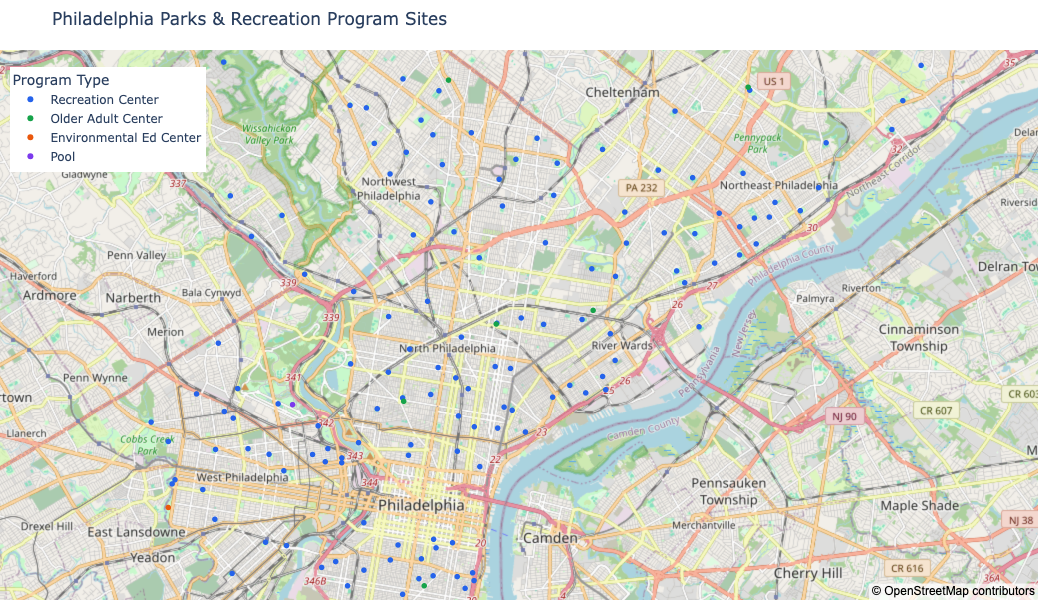

In [79]:
# Interactive scatter map of all PPR sites
map_df = ppr_joined.dropna(subset=['latitude', 'longitude', 'neighborhood']).copy()
map_df['neighborhood'] = map_df['neighborhood'].fillna('Unknown')

# Labels
type_labels = {
    'PPR_REC': 'Recreation Center',
    'OLDER_ADULT_CENTER': 'Older Adult Center',
    'ENVIRONMENTAL_EDUCATION_CENTER': 'Environmental Ed Center',
    'POOL': 'Pool'
}
map_df['Program Type'] = map_df['program_type'].map(type_labels).fillna(map_df['program_type'])

fig = px.scatter_map(
    map_df,
    lat='latitude',
    lon='longitude',
    color='Program Type',
    hover_name='park_name',
    hover_data={'neighborhood': True, 'Program Type': True, 'latitude': False, 'longitude': False},
    color_discrete_sequence=['#2563eb', '#16a34a', '#ea580c', '#7c3aed'],
    zoom=11,
    center={'lat': 40.00, 'lon': -75.13},
    map_style='open-street-map',   # free, no API key needed
    title='Philadelphia Parks & Recreation Program Sites',
    width=900,
    height=600
)

fig.update_layout(
    legend=dict(title='Program Type', yanchor='top', y=0.97, xanchor='left', x=0.01),
    margin={'r': 0, 't': 50, 'l': 0, 'b': 0}
)

fig.show()
fig.write_html('map_ppr_sites_interactive.html')


## Neighborhoods with NO programs

Which Philadelphia neighborhoods have zero PPR sites? 

In [76]:
nbhd_with_sites = set(ppr_joined['neighborhood'].dropna().unique())
all_neighborhoods = set(nbhd['LISTNAME'].unique())
no_programs = sorted(all_neighborhoods - nbhd_with_sites)

print(f'Total Philadelphia neighborhoods: {len(all_neighborhoods)}')
print(f'Neighborhoods WITH at least 1 PPR site: {len(nbhd_with_sites)}')
print(f'Neighborhoods with NO PPR site: {len(no_programs)}')
print()
print('Neighborhoods with zero PPR sites:')
for n in no_programs:
    print(f'  • {n}')

Total Philadelphia neighborhoods: 159
Neighborhoods WITH at least 1 PPR site: 92
Neighborhoods with NO PPR site: 67

Neighborhoods with zero PPR sites:
  • Airport
  • Aston-Woodbridge
  • Bartram Village
  • Belmont
  • Blue Bell Hill
  • Burholme
  • Byberry
  • Callowhill
  • Cedar Park
  • Center City East
  • Chinatown
  • Crescentville
  • Crestmont Farms
  • Dearnley Park
  • Dunlap
  • East Kensington
  • East Parkside
  • Eastwick
  • Fairmount
  • Franklin Mills
  • Franklinville
  • Garden Court
  • Germantown, Penn Knox
  • Germantown, West Central
  • Germantown, Westside
  • Germany Hill
  • Glenwood
  • Haverford North
  • Industrial
  • Lexington Park
  • Logan Square
  • Lower Moyamensing
  • Ludlow
  • McGuire
  • Mechanicsville
  • Melrose Park Gardens
  • Mount Airy, West
  • Navy Yard
  • Nicetown
  • Normandy Village
  • Northeast Phila Airport
  • Old City
  • Packer Park
  • Pennypack
  • Pennypack Woods
  • Penrose
  • Port Richmond
  • Powelton
  • Rittenhouse

## Chorpleth Map of the Amount of Rec Centers per Neighborhood

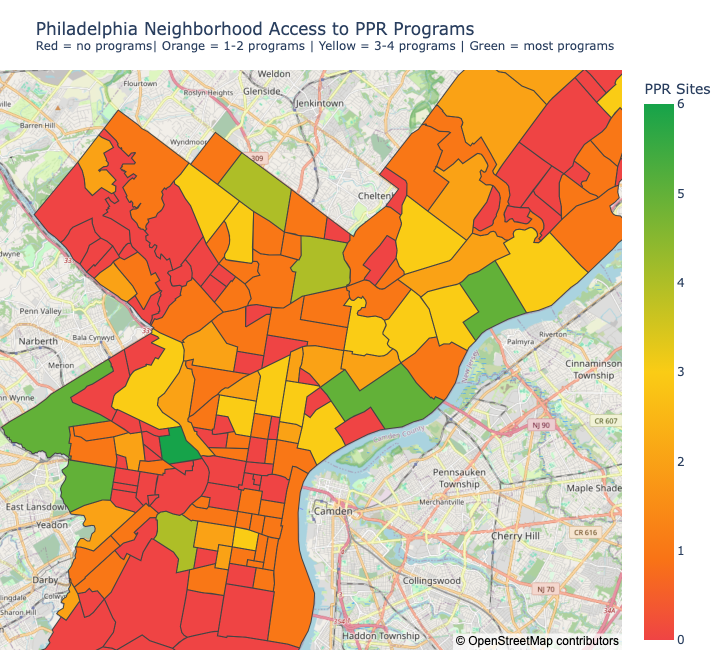

In [64]:

nbhd_map = nbhd.merge(
    nbhd_counts.rename(columns={'neighborhood': 'LISTNAME'}),
    on='LISTNAME',
    how='left'
)
nbhd_map['total_sites'] = nbhd_map['total_sites'].fillna(0).astype(int)
nbhd_map['access_tier'] = nbhd_map['total_sites'].apply(
    lambda x: 'No Programs' if x == 0 else ('1 site' if x == 1 else f'{x} sites')
)

import json
geojson_str = nbhd_map[['LISTNAME', 'total_sites', 'geometry']].to_json()
geojson_dict = json.loads(geojson_str)
# Add id field for Plotly
for feat in geojson_dict['features']:
    feat['id'] = feat['properties']['LISTNAME']

fig3 = px.choropleth_map(
    nbhd_map,
    geojson=geojson_dict,
    locations='LISTNAME',
    color='total_sites',
    color_continuous_scale=[
        [0.0,  '#ef4444'],   # 0 sites  → red   (enrichment desert)
        [0.15, '#f97316'],   # few      → orange
        [0.5,  '#facc15'],   # moderate → yellow
        [1.0,  '#16a34a']    # many     → green  (well-served)
    ],
    map_style='open-street-map',   # free, no API key needed
    zoom=10.5,
    center={'lat': 40.00, 'lon': -75.13},
    labels={'total_sites': 'PPR Sites', 'LISTNAME': 'Neighborhood'},
    hover_data={'LISTNAME': True, 'total_sites': True},
    title='Philadelphia Neighborhood Access to PPR Programs'
         '<br><sup>Red = no programs| Orange = 1-2 programs | Yellow = 3-4 programs | Green = most programs</sup>',
    width=900,
    height=650
)

fig3.update_layout(
    margin={'r': 0, 't': 70, 'l': 0, 'b': 0},
    coloraxis_colorbar=dict(title='PPR Sites')
)

fig3.show()
fig3.write_html('map_choropleth_access.html')



## PHILADELPHIA ENRICHMENT ACCESS GAP — FINDINGS



In [78]:
print(f'  Total PPR program sites:             {total_sites}')
print(f'  Total neighborhoods:                 159')
print(f'  Neighborhoods with ≥1 PPR site:      {n_with_sites}')
print(f'  Neighborhoods with ZERO PPR sites:   {n_no_sites}')
print(f'  Neighborhood with most sites:        {top_nbhd["neighborhood"]} ({top_nbhd["total_sites"]})')
print('This shows that there are rec desert clusters in southern parts of Philly and Roxborough areas.')



  Total PPR program sites:             168
  Total neighborhoods:                 159
  Neighborhoods with ≥1 PPR site:      92
  Neighborhoods with ZERO PPR sites:   67
  Neighborhood with most sites:        Mantua (6)
This shows that there are rec desert clusters in southern parts of Philly and Roxborough areas.
